<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta9_g%C3%B6rev3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Düzenleme süresi (piksel / 2): 30.7576 ms (0.030758 s)


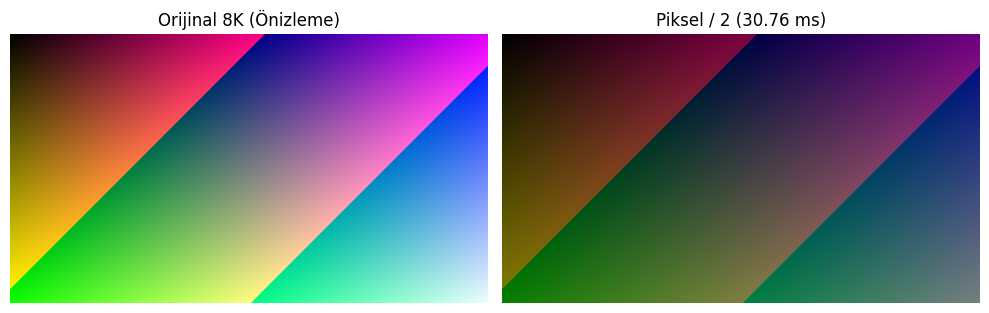

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

raw_8k_path = "orijinal_8k.bmp"
edited_8k_path = "bolunmus_8k.bmp"

h_8k, w_8k = 4320, 7680
y_idx, x_idx = np.ogrid[:h_8k, :w_8k]
img_8k_create = np.zeros((h_8k, w_8k, 3), dtype=np.uint8)
img_8k_create[:, :, 0] = (x_idx * 255 // w_8k).astype(np.uint8)
img_8k_create[:, :, 1] = (y_idx * 255 // h_8k).astype(np.uint8)
img_8k_create[:, :, 2] = (((x_idx + y_idx) // 16) % 256).astype(np.uint8)

cv2.imwrite(raw_8k_path, img_8k_create)

img_8k = cv2.imread(raw_8k_path, cv2.IMREAD_COLOR)
assert img_8k is not None, "8K BMP açılamadı!"

t_start = time.perf_counter()
img_8k_edited = img_8k // 2
t_end = time.perf_counter()

elapsed_ms = (t_end - t_start) * 1000
print(f"Düzenleme süresi (piksel / 2): {elapsed_ms:.4f} ms ({elapsed_ms / 1000:.6f} s)")

cv2.imwrite(edited_8k_path, img_8k_edited)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.resize(cv2.cvtColor(img_8k, cv2.COLOR_BGR2RGB), (640, 360)))
plt.title("Orijinal 8K (Önizleme)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.resize(cv2.cvtColor(img_8k_edited, cv2.COLOR_BGR2RGB), (640, 360)))
plt.title(f"Piksel / 2 ({elapsed_ms:.2f} ms)")
plt.axis("off")

plt.tight_layout()
plt.show()